# Creating A Fraud Detection System Using XG Boost Algorithms
## Steps
* 1. DataSet Load
* 2. EDA
* 3. Feature Engineering
* 4. Normalization
* 5. Train Test Split
* 6. Training Model
* 7. Performance Evaluation


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## DataSets Load

In [5]:
data_path = "data/raw/fraud_datasets/"

# Load datasets into separate DataFrames
df_ieee = pd.read_parquet(
    data_path + "ieee_cis_card_payments_real.parquet"
)

df_baf_bank = pd.read_parquet(
    data_path + "baf_bank_account_opening_synthetic.parquet"
)

df_mobile = pd.read_parquet(
    data_path + "momtsim_mobile_money_synthetic.parquet"
)

df_paysim = pd.read_parquet(
    data_path + "paysim_mobile_money_synthetic.parquet"
)

df_xente = pd.read_parquet(
    data_path + "xente_mobile_money_uganda_real.parquet"
)

# Display dataset shapes
print("IEEE Dataset Shape:", df_ieee.shape)
print("BAF Bank Dataset Shape:", df_baf_bank.shape)
print("Mobile Dataset Shape:", df_mobile.shape)
print("PaySim Dataset Shape:", df_paysim.shape)
print("Xente Dataset Shape:", df_xente.shape)

IEEE Dataset Shape: (590540, 438)
BAF Bank Dataset Shape: (1000000, 36)
Mobile Dataset Shape: (4225958, 9)
PaySim Dataset Shape: (6362620, 9)
Xente Dataset Shape: (95662, 19)


# EDA

## Organize all five datasets

In [7]:
datasets = {
    "IEEE-CIS": df_ieee,
    "BAF Bank": df_baf_bank,
    "MoMTSim": df_mobile,
    "PaySim": df_paysim,
    "Xente": df_xente
}

In [8]:
import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

## Dataset overview

In [25]:
overviews = []
for name, df in datasets.items():
    overviews.append({
        "Dataset" : name,
        "Rows" : df.shape[0],
        "Columns" : df.shape[1],
        "Memory Usage (MB)" : df.memory_usage(deep=True).sum() / (1024 ** 2),
        "Duplicate values" : df.duplicated().sum(),
        "Missing values" : df.isnull().sum().sum()
    })


overview_df = pd.DataFrame(overviews)
display(overview_df)

,Dataset,Rows,Columns,Memory Usage (MB),Duplicate values,Missing values
0,IEEE-CIS,590540,438,1987.084721,0,116704153
1,BAF Bank,1000000,36,267.835821,0,2000000
2,MoMTSim,4225958,9,331.204360,78,0
3,PaySim,6362620,9,445.299754,0,0
4,Xente,95662,19,23.237210,0,0


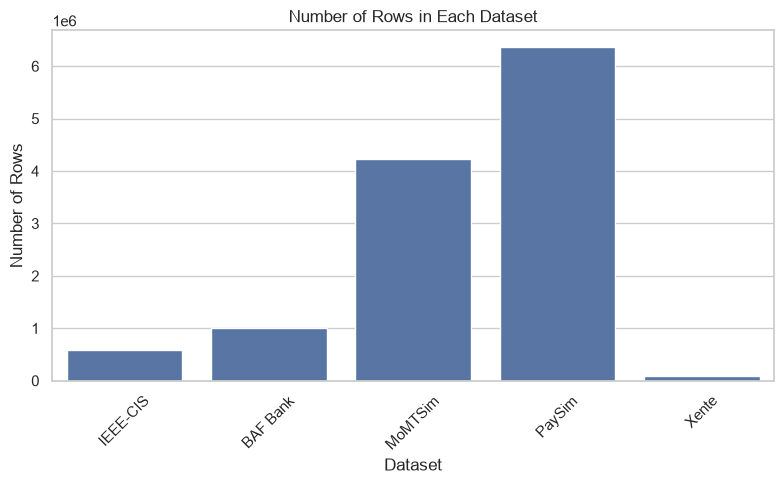

In [30]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=overview_df,
    x = "Dataset",
    y = "Rows"
)

plt.title("Number of Rows in Each Dataset")
plt.xlabel("Dataset")
plt.ylabel("Number of Rows")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Data types analysis

In [31]:
for name, df in datasets.items():
    print("\n" + "=" * 60)
    print(f"DATASET: {name}")
    print("=" * 60)

    print("Numerical Features:", len(df.select_dtypes(include=np.number).columns))
    print("Categorical Features:", len(df.select_dtypes(include=["object", "category"]).columns))
    print("Datetime Features:", len(df.select_dtypes(include=["datetime"]).columns))

    print("\nData Types:")
    print(df.dtypes.value_counts())

    print("\nColumn Names:")
    print(df.columns.tolist())



DATASET: IEEE-CIS
Numerical Features: 403
Categorical Features: 33
Datetime Features: 0

Data Types:
float64     399
str          31
int64         3
category      1
category      1
int8          1
string        1
boolean       1
Name: count, dtype: int64

Column Names:
['dataset', 'split', 'ts', 'label', 'user_id', 'seen_user', 'TransactionID', 'TransactionAmt', 'ProductCD', 'card1', 'card2', 'card3', 'card4', 'card5', 'card6', 'addr1', 'addr2', 'dist1', 'dist2', 'P_emaildomain', 'R_emaildomain', 'C1', 'C2', 'C3', 'C4', 'C5', 'C6', 'C7', 'C8', 'C9', 'C10', 'C11', 'C12', 'C13', 'C14', 'D1', 'D2', 'D3', 'D4', 'D5', 'D6', 'D7', 'D8', 'D9', 'D10', 'D11', 'D12', 'D13', 'D14', 'D15', 'M1', 'M2', 'M3', 'M4', 'M5', 'M6', 'M7', 'M8', 'M9', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'V29', 'V30', 'V31', 'V32', 'V33', 'V34', 'V35', 'V36', 'V37', 'V38', '

## Missing values analysis

In [32]:
for name, df in datasets.items():
    missing = pd.DataFrame({
        "Missing Counts" : df.isnull().sum(),
        "Missing Percentage" : (df.isnull().sum() / len(df)) * 100
    })

    missing = missing[missing["Missing Counts"] > 0].sort_values(by="Missing Percentage", ascending=False)

    print(f"\{name} Dataset - Missing Values Analysis")
    display(missing.head(30))

\IEEE-CIS Dataset - Missing Values Analysis


,Missing Counts,Missing Percentage
user_id,590540,100.000000
seen_user,590540,100.000000
id_24,585793,99.196159
id_25,585408,99.130965
id_07,585385,99.127070
id_08,585385,99.127070
id_21,585381,99.126393
id_26,585377,99.125715
id_27,585371,99.124699
id_23,585371,99.124699


\BAF Bank Dataset - Missing Values Analysis


,Missing Counts,Missing Percentage
user_id,1000000,100.0
seen_user,1000000,100.0


\MoMTSim Dataset - Missing Values Analysis


,Missing Counts,Missing Percentage


\PaySim Dataset - Missing Values Analysis


,Missing Counts,Missing Percentage


\Xente Dataset - Missing Values Analysis


,Missing Counts,Missing Percentage


### Visualize missing values

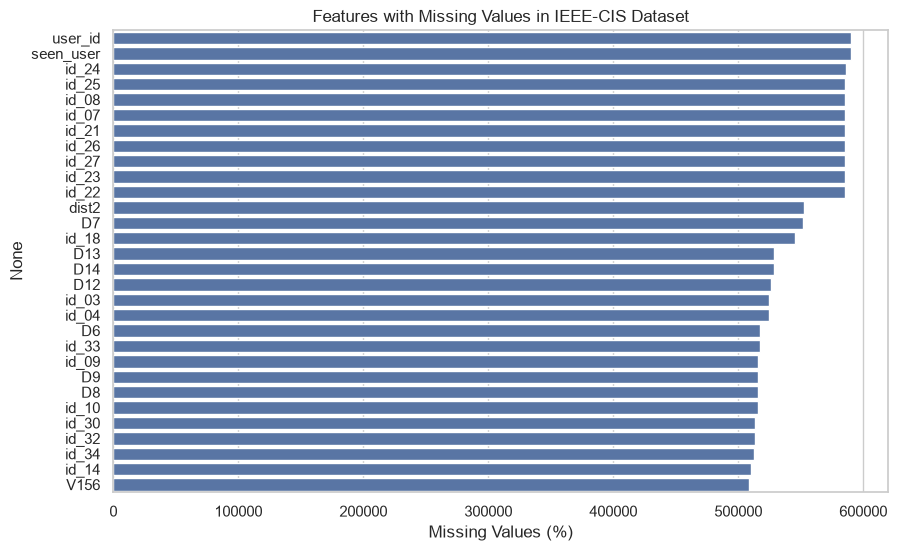

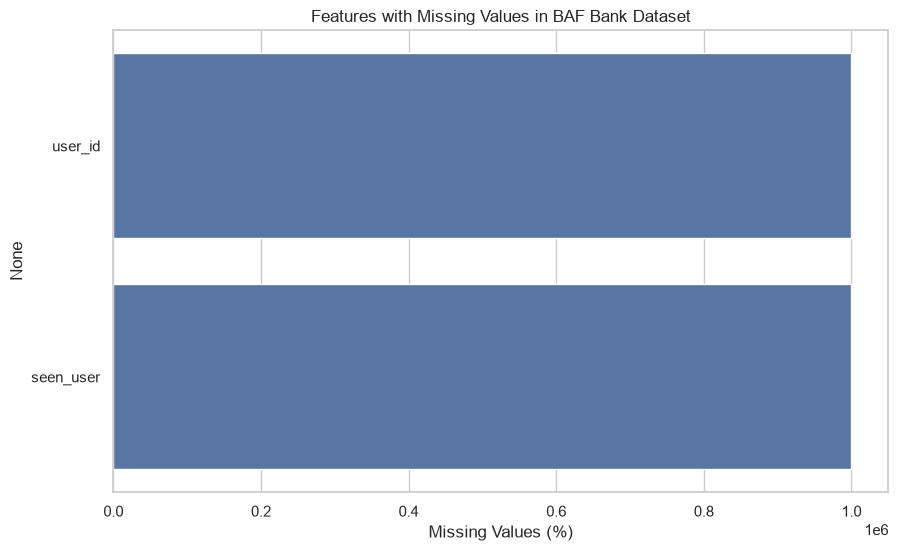


MoMTSim Dataset - No Missing Values

PaySim Dataset - No Missing Values

Xente Dataset - No Missing Values


In [43]:
for name, df in datasets.items():
    missing = (
        df.isnull().sum()
    ).sort_values(ascending=False)

    missing = missing[missing > 0].head(30)

    if len(missing) == 0:
        print(f"\n{name} Dataset - No Missing Values")
        continue

    plt.figure(figsize=(10, 6))
    sns.barplot(
        x = missing.values,
        y = missing.index
    )

    plt.title(f"Features with Missing Values in {name} Dataset")
    plt.xlabel("Missing Values (%)")
    plt.show()

## Duplicate records analysis

In [42]:
duplicate_results = []
for name, df in datasets.items():
    duplicate_count = df.duplicated().sum()
    duplicate_percentage = (duplicate_count / len(df)) * 100

    duplicate_results.append({
        "Dataset" : name,
        "Duplicate Counts" : duplicate_count,
        "Duplicate Percentage" : duplicate_percentage
    })


duplicate_df = pd.DataFrame(duplicate_results)
display(duplicate_df)

,Dataset,Duplicate Counts,Duplicate Percentage
0,IEEE-CIS,0,0.000000
1,BAF Bank,0,0.000000
2,MoMTSim,78,0.001846
3,PaySim,0,0.000000
4,Xente,0,0.000000


In [ ]:
for name, df in datasets.items():
    duplicates = (
        df.duplicated().sum()
    ).sort_values(ascending=False)

    duplicates = duplicates[duplicates > 0].head(30)

    if len(duplicates) == 0:
        print(f"\n{name} Dataset - No Duplicates")
        continue

    plt.figure(figsize=(10, 6))
    sns.barplot(
        x = duplicates.values,
        y = duplicates.index
    )

    plt.title(f"Features with Duplicates in {name} Dataset")
    plt.xlabel("Duplicates (%)")
    plt.show()